# Measurements

A wall thickness map shows at a glance where a part is too thin to machine, cast or print. `px.PlotField` draws such
maps from a measurement, a function of an object such as the thinnest wall from `planex.measurements`. The
measurement's samples color the faces, interpolated between them, or the edges with `on="edges"`. The plot includes
a color bar, the measured value in the title and the measurement's marks, such as where the wall is thinnest. A
function of your own is drawn the same way when it returns its samples. See [Part analysis](../measuring/analysis.md)
for what measurements are and how they are stored on a sketch.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import planex as px
import planex.measurements as pm

In [2]:
import warnings

warnings.simplefilter("ignore", px.PlanexWarning)

## A wall thickness map

The example is a flange of diameter 120 with a bore of 40 and six bolt holes of 8 on a pitch circle of 80.
`pm.MinThickness()` rolls the largest disc that fits along the boundary. Over the faces, every point takes the value
of the largest disc that covers it (a), here with `samples=900` along the boundary instead of the default 400, for a
smoother map. With `on="edges"`, the samples color the boundary itself (b). The marks show where the wall is
thinnest.

thinnest wall 15.999999999998174


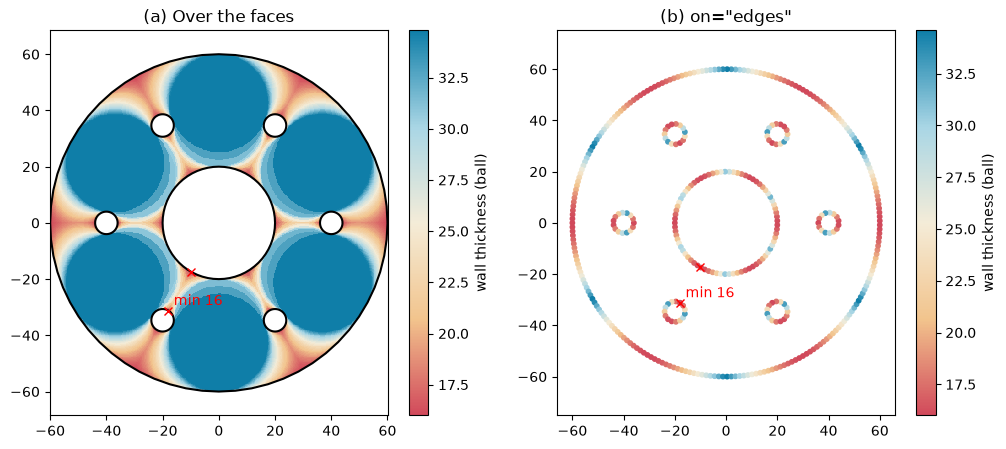

In [3]:
hole = px.Circle((40, 0), 4).Face()
holes = [hole.Rotated((0, 0), 60 * k) for k in range(6)]
flange = px.Subtract([px.Circle((0, 0), 60).Face(), px.Circle((0, 0), 20).Face(), *holes])
print("thinnest wall", flange.Measure(pm.MinThickness()))

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5))
px.PlotField(pm.MinThickness(), flange, ax=left, samples=900)
px.PlotField(pm.MinThickness(), flange, ax=right, on="edges")
left.set_title("(a) Over the faces")
right.set_title('(b) on="edges"');

`method="ray"` measures along the inward normal to the other side instead of with a disc. On the boundary of a bolt
hole, the ray finds the full wall to the rim or to the bore, while the disc finds the narrowest gap it fits through.
The ray's map is therefore never thinner than the disc's. The example draws both with the same color range, 0 to 40,
so that their colors compare (a, b).

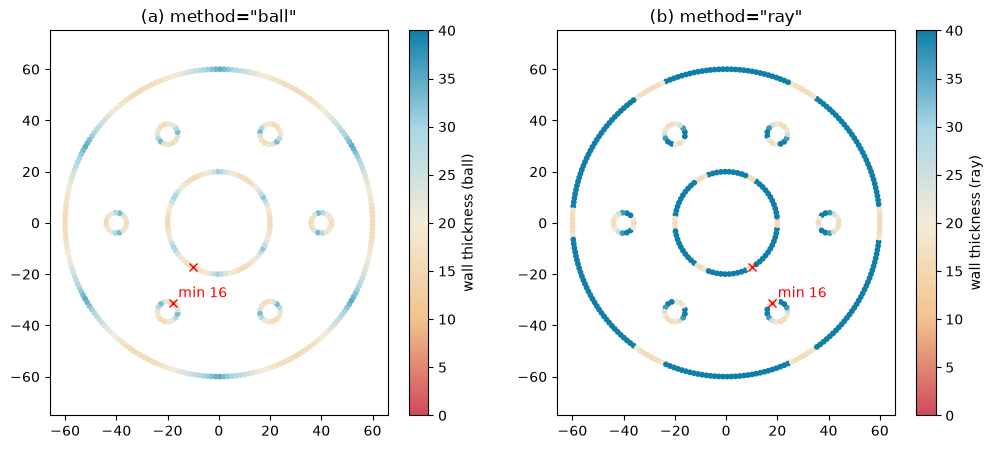

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5))
px.PlotField(pm.MinThickness(), flange, ax=left, on="edges", min=0, max=40)
px.PlotField(pm.MinThickness(method="ray"), flange, ax=right, on="edges", min=0, max=40)
left.set_title('(a) method="ball"')
right.set_title('(b) method="ray"');

## Measurements of your own

A measurement of your own is a function of the object. It returns the measured value, and with `plot=True`, a
dictionary of its samples:

- `points`: the sample points, as a list of (h, v) or an (n, 2) array;
- `values`: one value per point;
- `label`: the name of the color bar;
- `value`: the measured value, shown in the title;
- `marks`: a list of (point, text), such as the point where the value is reached.

Over the faces, the values are interpolated between the points. On the edges, each edge takes the values of the
points on it. A `samples` argument is optional, and `px.PlotField(..., samples=)` passes it on.

The first example samples the distance to the nearest bolt hole on a grid over the flange. `Contains` keeps the grid
points inside the flange, and `Distance` measures them to the bolt holes, both for the whole array at once. The
farthest point is where a bolt pulls least, on the rim between two holes.

farthest from a bolt hole 28.296719056812798


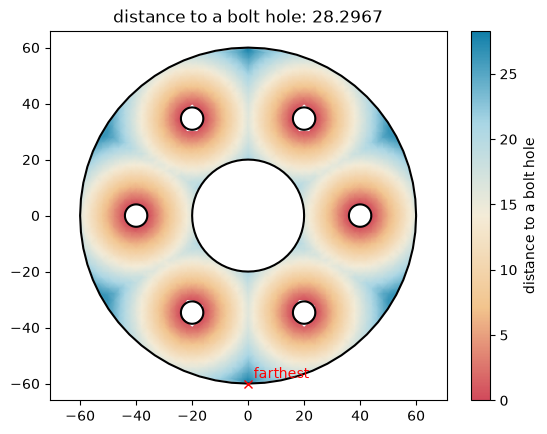

In [5]:
bolts = px.Compound(holes)


def nearest_hole(face, plot=False, samples=61):
    (h0, v0), (h1, v1) = face.bounding_box
    h, v = np.meshgrid(np.linspace(h0, h1, samples), np.linspace(v0, v1, samples))
    points = np.column_stack([h.ravel(), v.ravel()])
    points = points[face.Contains(points)]
    values = bolts.Distance(points)
    far = values.argmax()
    if not plot:
        return values[far]
    return {"points": points, "values": values, "label": "distance to a bolt hole", "value": values[far],
            "marks": [(tuple(points[far]), "farthest")]}


print("farthest from a bolt hole", flange.Measure(nearest_hole))
px.PlotField(nearest_hole, flange);

The second example samples the radius of a cam along its outline and draws it on the edges, so that the rise and the
fall show on the profile itself. The cam is a periodic spline through six points.

largest radius 30.05581292767293


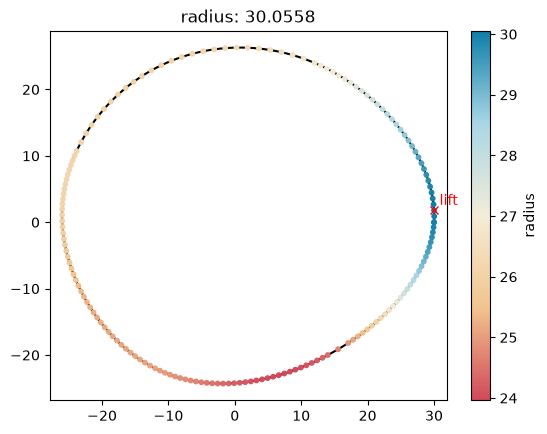

In [6]:
knots = [(30, 0), (12, 24), (-14, 22), (-26, 2), (-12, -22), (14, -20)]
cam = px.Spline(knots, periodic=True).Face()


def radius(face, plot=False):
    points = face.outer.Polylines(0.05)[0]
    values = np.hypot(points[:, 0], points[:, 1])
    top = values.argmax()
    if not plot:
        return values[top]
    return {"points": points, "values": values, "label": "radius", "value": values[top],
            "marks": [(tuple(points[top]), "lift")]}


print("largest radius", cam.Measure(radius))
px.PlotField(radius, cam, on="edges");